                     NSL-KDD  UNSW-NB15  CICIDS2017
Logistic Regression   0.9073     0.8126      0.8450
KNN                   0.9916     0.8132      0.9826
Decision Tree         0.9960     0.8296      0.9952
Random Forest         0.9978     0.8664      0.9949
SVM                   0.9832     0.8261      0.8296


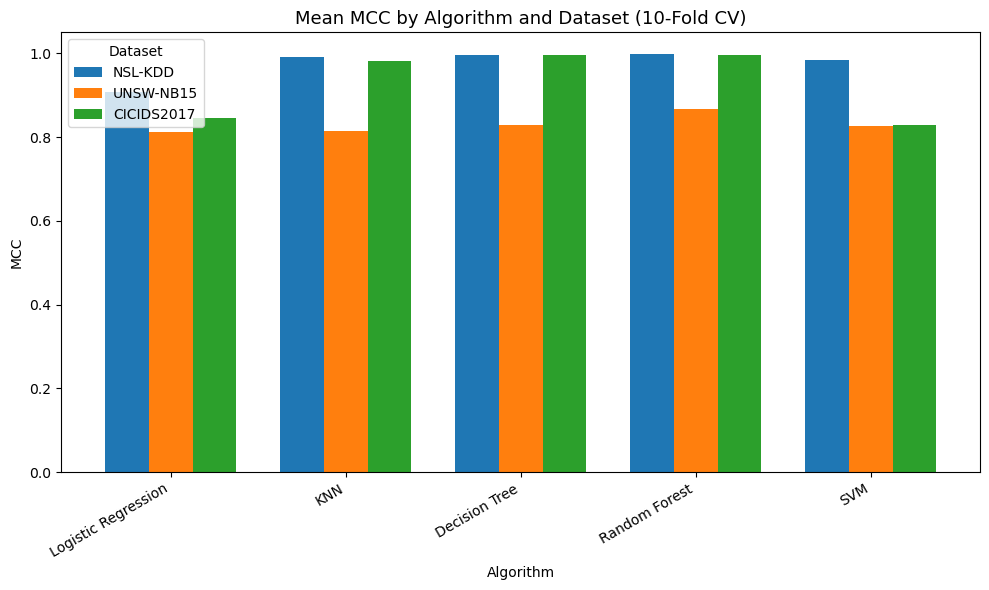

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# ---- LOAD PHASE 1 SUMMARY RESULTS ----
nslkdd = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\NSL-KDD\results\Phase1_NSLKDD_summary.csv", index_col=0)
unsw = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\UNSW-NB15\results\Phase1_UNSWNB15_summary.csv", index_col=0)
cicids = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\CIC-IDS2017\results\Phase1_CICIDS2017_summary.csv", index_col=0)

# Output folder for all charts
charts_folder = r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\Charts"
os.makedirs(charts_folder, exist_ok=True)

# ---- BUILD COMBINED MCC TABLE ----
mcc_table = pd.DataFrame({
    'NSL-KDD': nslkdd['mcc'],
    'UNSW-NB15': unsw['mcc'],
    'CICIDS2017': cicids['mcc']
})

print(mcc_table)

# ---- PLOT ----
fig, ax = plt.subplots(figsize=(10, 6))
mcc_table.plot(kind='bar', ax=ax, width=0.75)
ax.set_title('Mean MCC by Algorithm and Dataset (10-Fold CV)', fontsize=13)
ax.set_ylabel('MCC')
ax.set_xlabel('Algorithm')
ax.set_ylim(0, 1.05)
ax.legend(title='Dataset')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig(os.path.join(charts_folder, "01_bar_mcc_by_algorithm_dataset.png"), dpi=300)
plt.show()

C:\Users\icevo\AppData\Local\Temp\ipykernel_2192\4273536154.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(mcc_data, labels=algorithms)
C:\Users\icevo\AppData\Local\Temp\ipykernel_2192\4273536154.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(mcc_data, labels=algorithms)
C:\Users\icevo\AppData\Local\Temp\ipykernel_2192\4273536154.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(mcc_data, labels=algorithms)


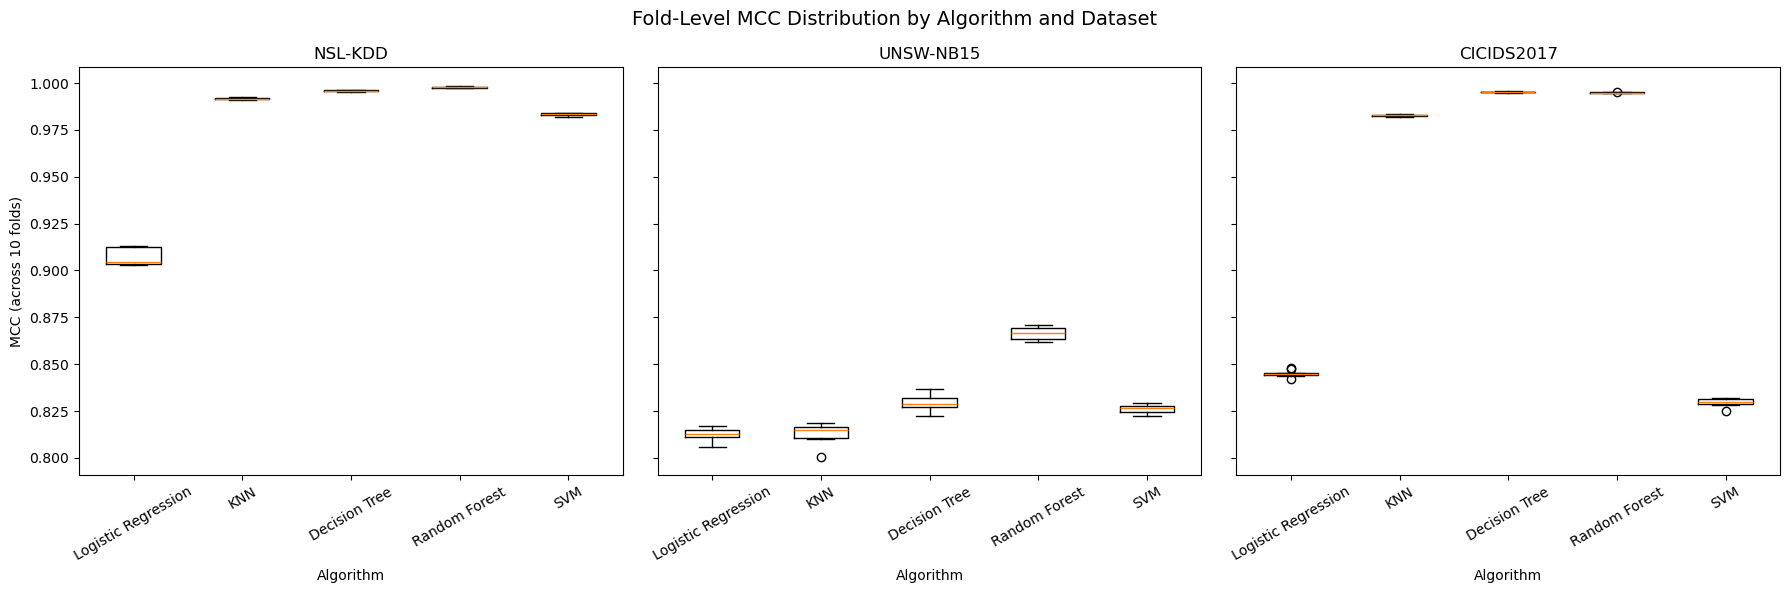

In [2]:
# ---- LOAD FOLD-LEVEL RESULTS ----
nslkdd_fold = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\NSL-KDD\results\Phase1_NSLKDD_foldlevel.csv", header=[0,1], index_col=0)
unsw_fold = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\UNSW-NB15\results\Phase1_UNSWNB15_foldlevel.csv", header=[0,1], index_col=0)
cicids_fold = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\CIC-IDS2017\results\Phase1_CICIDS2017_foldlevel.csv", header=[0,1], index_col=0)

datasets_fold = {
    'NSL-KDD': nslkdd_fold,
    'UNSW-NB15': unsw_fold,
    'CICIDS2017': cicids_fold
}

algorithms = ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'SVM']

# ---- ONE BOXPLOT PER DATASET (MCC across folds) ----
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

for ax, (dataset_name, fold_df) in zip(axes, datasets_fold.items()):
    mcc_data = [fold_df[(algo, 'mcc')].values for algo in algorithms]
    ax.boxplot(mcc_data, labels=algorithms)
    ax.set_title(dataset_name)
    ax.set_xlabel('Algorithm')
    ax.tick_params(axis='x', rotation=30)

axes[0].set_ylabel('MCC (across 10 folds)')
fig.suptitle('Fold-Level MCC Distribution by Algorithm and Dataset', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(charts_folder, "02_boxplot_mcc_distribution.png"), dpi=300)
plt.show()

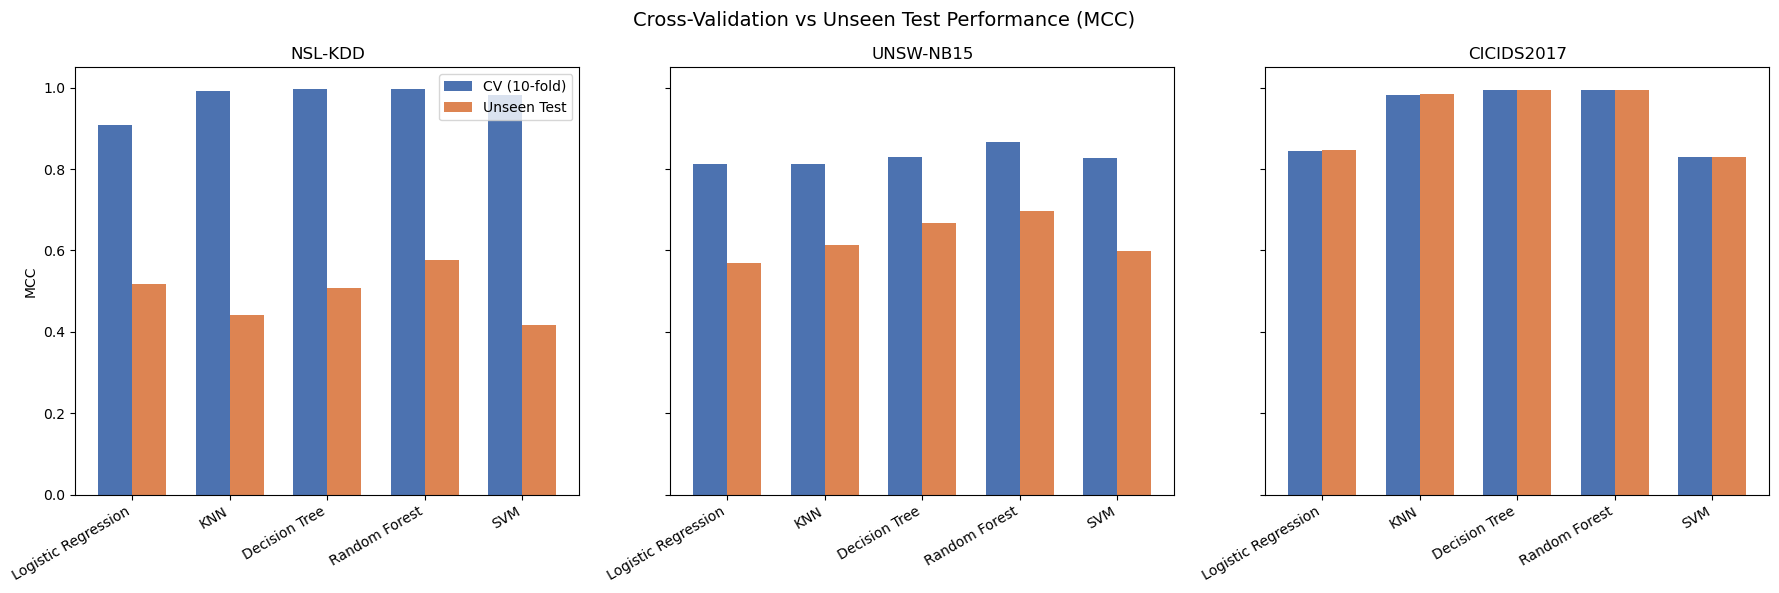

In [3]:
# ---- LOAD UNSEEN TEST RESULTS ----
nslkdd_unseen = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\UnseenTesting_results\UnseenTest_NSLKDD.csv", index_col=0)
unsw_unseen = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\UnseenTesting_results\UnseenTest_UNSWNB15.csv", index_col=0)
cicids_unseen = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\UnseenTesting_results\UnseenTest_CICIDS2017.csv", index_col=0)

datasets_cv = {'NSL-KDD': nslkdd, 'UNSW-NB15': unsw, 'CICIDS2017': cicids}
datasets_unseen = {'NSL-KDD': nslkdd_unseen, 'UNSW-NB15': unsw_unseen, 'CICIDS2017': cicids_unseen}

fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

for ax, dataset_name in zip(axes, datasets_cv.keys()):
    cv_mcc = datasets_cv[dataset_name]['mcc']
    unseen_mcc = datasets_unseen[dataset_name]['mcc']

    x = np.arange(len(algorithms))
    width = 0.35

    ax.bar(x - width/2, cv_mcc.reindex(algorithms), width, label='CV (10-fold)', color='#4C72B0')
    ax.bar(x + width/2, unseen_mcc.reindex(algorithms), width, label='Unseen Test', color='#DD8452')

    ax.set_title(dataset_name)
    ax.set_xticks(x)
    ax.set_xticklabels(algorithms, rotation=30, ha='right')
    ax.set_ylim(0, 1.05)

axes[0].set_ylabel('MCC')
axes[0].legend()
fig.suptitle('Cross-Validation vs Unseen Test Performance (MCC)', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(charts_folder, "03_cv_vs_unseen_mcc.png"), dpi=300)
plt.show()

                     NSL-KDD  UNSW-NB15  CICIDS2017
Logistic Regression      5.0        5.0         4.0
KNN                      3.0        4.0         3.0
Decision Tree            2.0        2.0         1.0
Random Forest            1.0        1.0         2.0
SVM                      4.0        3.0         5.0


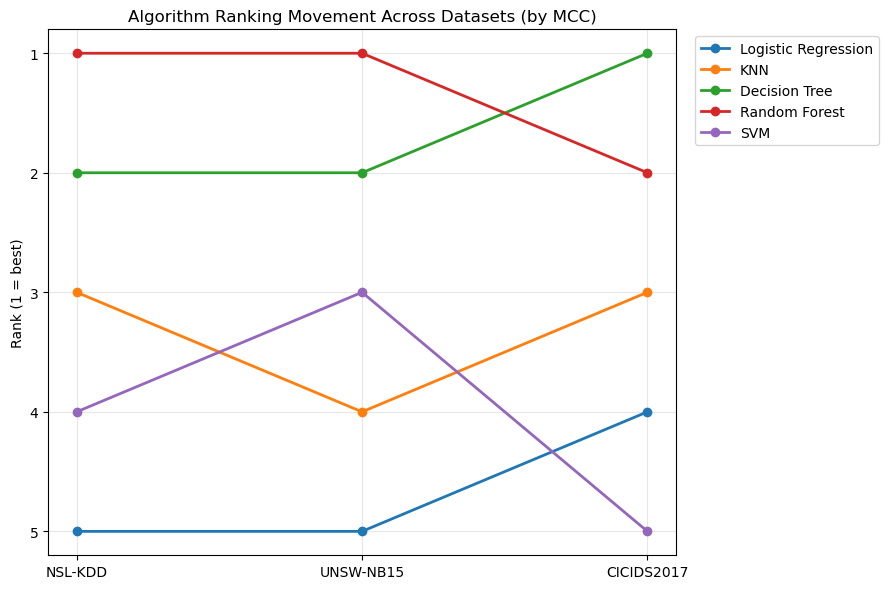

In [4]:
# ---- LOAD RANKINGS FROM PHASE 2 ----
rankings = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\Phase2_results\Phase2_algorithm_rankings.csv", index_col=0)

print(rankings)

# ---- LINE/SLOPE CHART SHOWING RANK MOVEMENT ACROSS DATASETS ----
fig, ax = plt.subplots(figsize=(9, 6))

datasets_order = ['NSL-KDD', 'UNSW-NB15', 'CICIDS2017']
colors = plt.cm.tab10.colors

for i, algo in enumerate(rankings.index):
    ax.plot(datasets_order, rankings.loc[algo, datasets_order], marker='o', linewidth=2, label=algo, color=colors[i])

ax.invert_yaxis()  # rank 1 (best) at top
ax.set_yticks([1, 2, 3, 4, 5])
ax.set_ylabel('Rank (1 = best)')
ax.set_title('Algorithm Ranking Movement Across Datasets (by MCC)')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(charts_folder, "04_ranking_movement_across_datasets.png"), dpi=300)
plt.show()

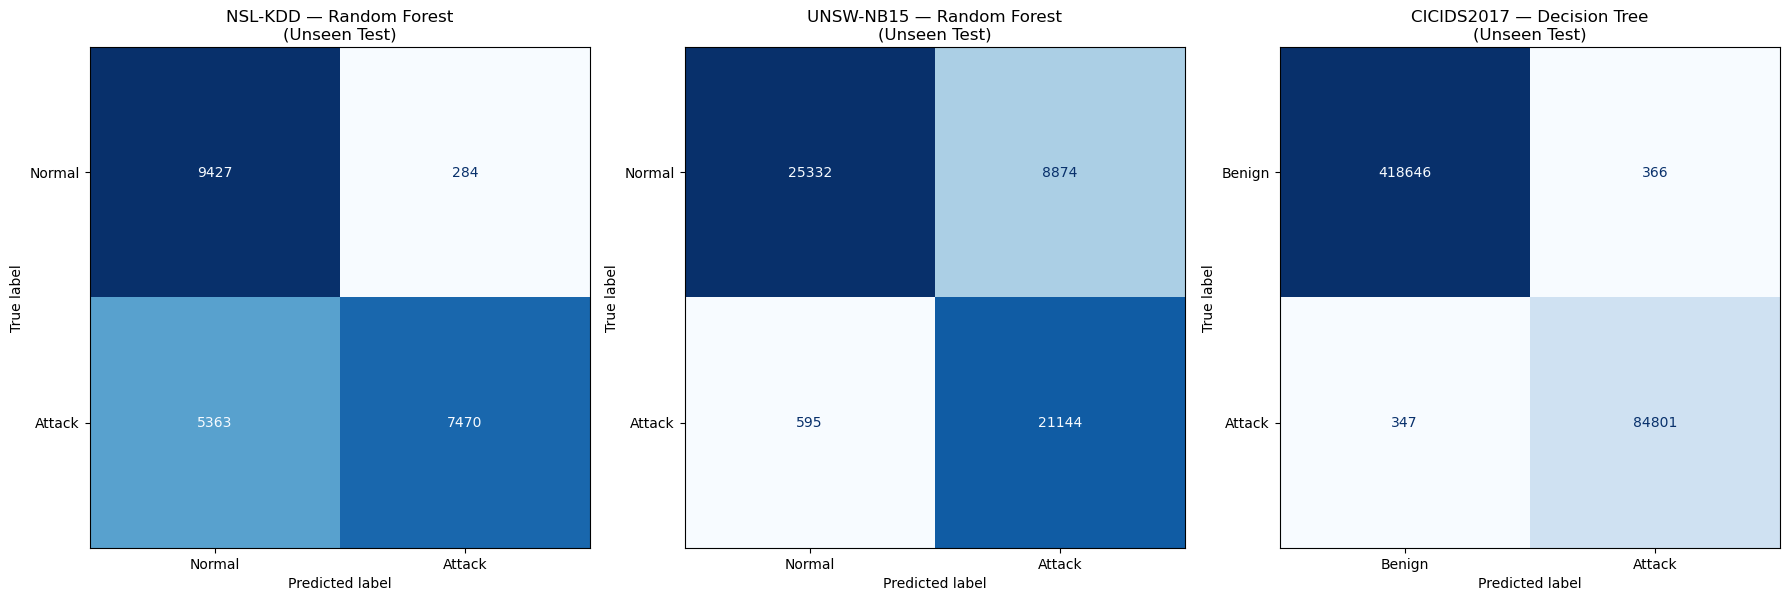

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ---- 1. NSL-KDD — Random Forest (best on NSL-KDD) ----
train_df_nsl = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\NSL-KDD\processed\NSLKDD_train_cleaned.csv")
test_df_nsl = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\NSL-KDD\processed\NSLKDD_test_cleaned.csv")

X_train_nsl = train_df_nsl.drop(columns=['label', 'binary_label', 'difficulty'])
y_train_nsl = train_df_nsl['binary_label']
X_test_nsl = test_df_nsl.drop(columns=['label', 'binary_label', 'difficulty'])
y_test_nsl = test_df_nsl['binary_label']

model_nsl = RandomForestClassifier(random_state=42)
model_nsl.fit(X_train_nsl, y_train_nsl)
y_pred_nsl = model_nsl.predict(X_test_nsl)
cm_nsl = confusion_matrix(y_test_nsl, y_pred_nsl, labels=['normal', 'attack'])

# ---- 2. UNSW-NB15 — Random Forest (best on UNSW-NB15) ----
train_df_unsw = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\UNSW-NB15\processed\UNSWNB15_train_cleaned.csv")
test_df_unsw = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\UNSW-NB15\processed\UNSWNB15_test_cleaned.csv")

X_train_unsw = train_df_unsw.drop(columns=['label', 'attack_cat'])
y_train_unsw = train_df_unsw['label']
X_test_unsw = test_df_unsw.drop(columns=['label', 'attack_cat'])
y_test_unsw = test_df_unsw['label']

model_unsw = RandomForestClassifier(random_state=42)
model_unsw.fit(X_train_unsw, y_train_unsw)
y_pred_unsw = model_unsw.predict(X_test_unsw)
cm_unsw = confusion_matrix(y_test_unsw, y_pred_unsw, labels=[0, 1])

# ---- 3. CICIDS2017 — Decision Tree (best on CICIDS2017) ----
train_df_cic = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\CIC-IDS2017\processed\CICIDS2017_train_cleaned.csv")
test_df_cic = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\CIC-IDS2017\processed\CICIDS2017_test_cleaned.csv")

X_train_cic = train_df_cic.drop(columns=['Label', 'binary_label'])
y_train_cic = train_df_cic['binary_label']
X_test_cic = test_df_cic.drop(columns=['Label', 'binary_label'])
y_test_cic = test_df_cic['binary_label']

model_cic = DecisionTreeClassifier(random_state=42)
model_cic.fit(X_train_cic, y_train_cic)
y_pred_cic = model_cic.predict(X_test_cic)
cm_cic = confusion_matrix(y_test_cic, y_pred_cic, labels=['BENIGN', 'ATTACK'])

# ---- 4. PLOT ALL THREE SIDE BY SIDE ----
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

ConfusionMatrixDisplay(cm_nsl, display_labels=['Normal', 'Attack']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('NSL-KDD — Random Forest\n(Unseen Test)')

ConfusionMatrixDisplay(cm_unsw, display_labels=['Normal', 'Attack']).plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('UNSW-NB15 — Random Forest\n(Unseen Test)')

ConfusionMatrixDisplay(cm_cic, display_labels=['Benign', 'Attack']).plot(ax=axes[2], cmap='Blues', colorbar=False)
axes[2].set_title('CICIDS2017 — Decision Tree\n(Unseen Test)')

plt.tight_layout()
plt.savefig(os.path.join(charts_folder, "05_confusion_matrices_best_models.png"), dpi=300)
plt.show()

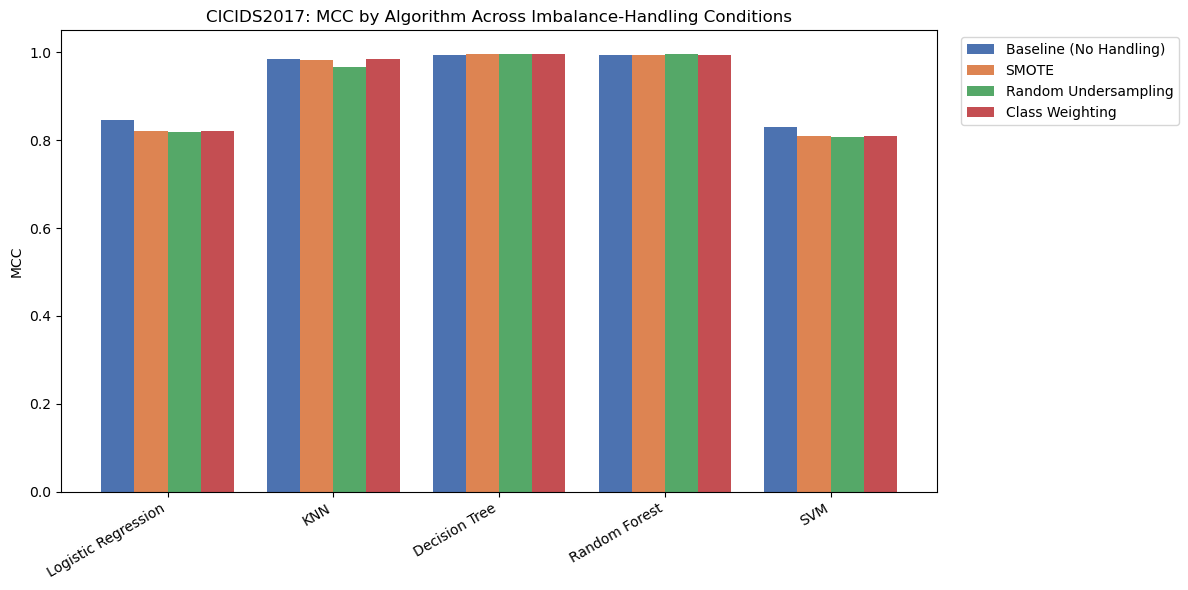

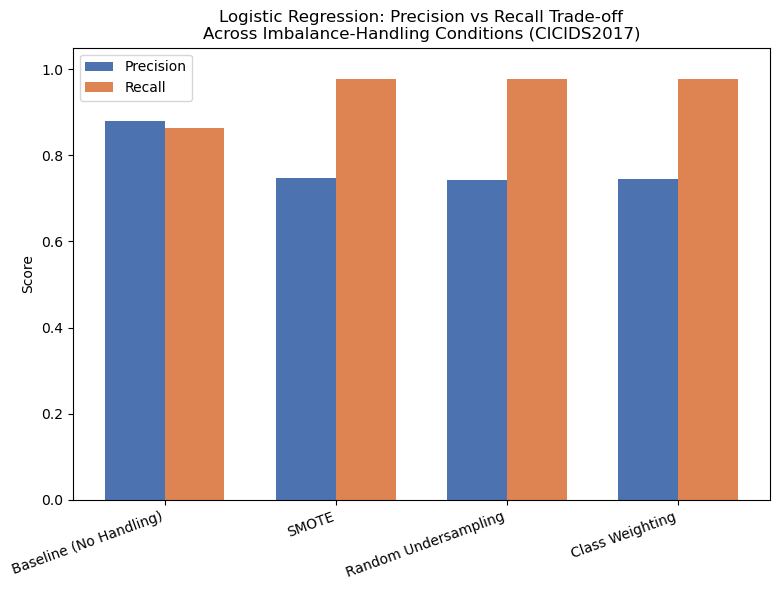

In [6]:
# ---- LOAD PHASE 3 RESULTS ----
phase3 = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\Phase3_results\Phase3_CICIDS2017_imbalance_comparison.csv")

conditions_order = ['Baseline (No Handling)', 'SMOTE', 'Random Undersampling', 'Class Weighting']
algorithms = ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'SVM']

# ---- CHART: MCC across conditions, grouped by algorithm ----
fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(algorithms))
width = 0.2
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

for i, condition in enumerate(conditions_order):
    condition_data = phase3[phase3['condition'] == condition].set_index('model').reindex(algorithms)
    ax.bar(x + (i - 1.5) * width, condition_data['mcc'], width, label=condition, color=colors[i])

ax.set_xticks(x)
ax.set_xticklabels(algorithms, rotation=30, ha='right')
ax.set_ylabel('MCC')
ax.set_title('CICIDS2017: MCC by Algorithm Across Imbalance-Handling Conditions')
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(os.path.join(charts_folder, "06_phase3_mcc_by_condition.png"), dpi=300)
plt.show()

# ---- CHART: Precision vs Recall trade-off for Logistic Regression (clearest trade-off example) ----
fig, ax = plt.subplots(figsize=(8, 6))

lr_data = phase3[phase3['model'] == 'Logistic Regression'].set_index('condition').reindex(conditions_order)

x = np.arange(len(conditions_order))
width = 0.35

ax.bar(x - width/2, lr_data['precision'], width, label='Precision', color='#4C72B0')
ax.bar(x + width/2, lr_data['recall'], width, label='Recall', color='#DD8452')

ax.set_xticks(x)
ax.set_xticklabels(conditions_order, rotation=20, ha='right')
ax.set_ylabel('Score')
ax.set_title('Logistic Regression: Precision vs Recall Trade-off\nAcross Imbalance-Handling Conditions (CICIDS2017)')
ax.legend()
ax.set_ylim(0, 1.05)
plt.tight_layout()
plt.savefig(os.path.join(charts_folder, "07_phase3_precision_recall_tradeoff.png"), dpi=300)
plt.show()

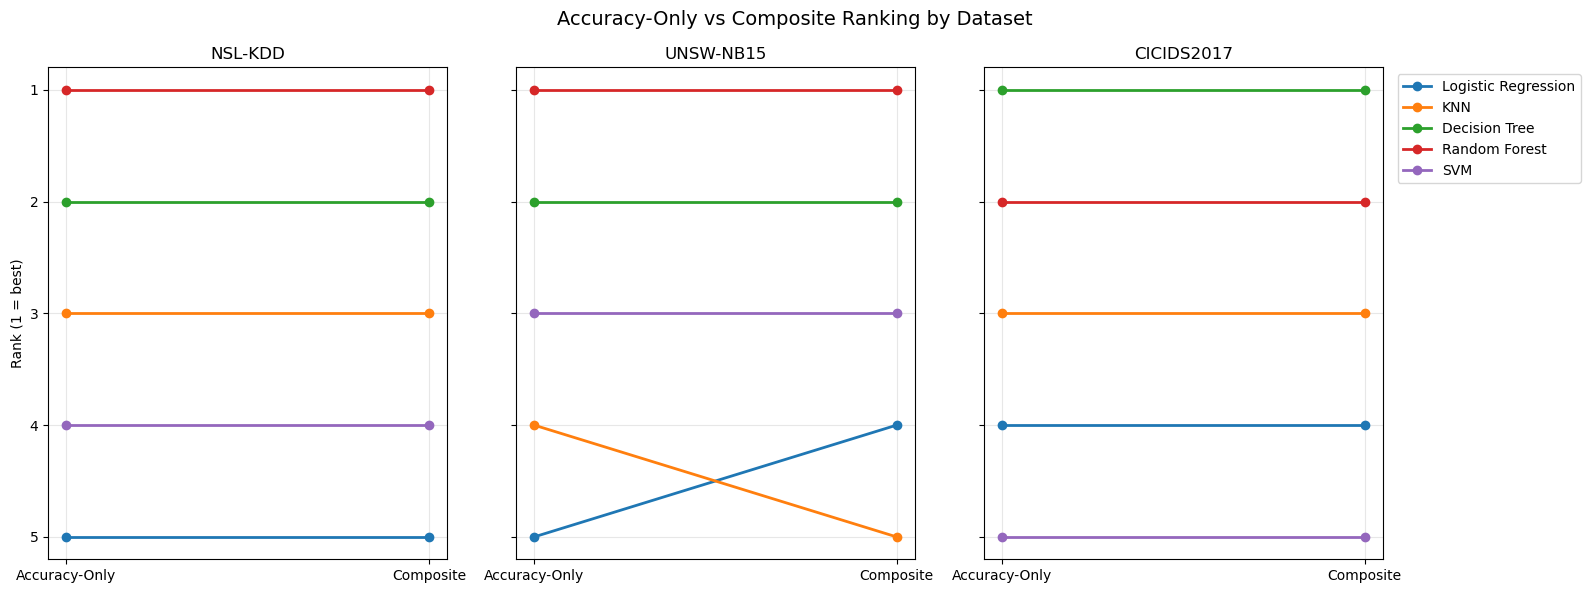

In [7]:
# ---- LOAD PHASE 4 RESULTS ----
nsl_comp = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\Phase4_results\Phase4_NSLKDD_composite_ranking.csv", index_col=0)
unsw_comp = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\Phase4_results\Phase4_UNSWNB15_composite_ranking.csv", index_col=0)
cicids_comp = pd.read_csv(r"C:\Users\icevo\OneDrive\Desktop\Dissertation\Datasets\Phase4_results\Phase4_CICIDS2017_composite_ranking.csv", index_col=0)

comp_datasets = {'NSL-KDD': nsl_comp, 'UNSW-NB15': unsw_comp, 'CICIDS2017': cicids_comp}

# ---- SLOPE CHART: accuracy_rank vs composite_rank, per dataset ----
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)

for ax, (dataset_name, df) in zip(axes, comp_datasets.items()):
    for algo in df.index:
        ax.plot(['Accuracy-Only', 'Composite'],
                 [df.loc[algo, 'accuracy_rank'], df.loc[algo, 'composite_rank']],
                 marker='o', linewidth=2, label=algo)
    ax.invert_yaxis()
    ax.set_yticks([1, 2, 3, 4, 5])
    ax.set_title(dataset_name)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('Rank (1 = best)')
axes[-1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
fig.suptitle('Accuracy-Only vs Composite Ranking by Dataset', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(charts_folder, "08_accuracy_vs_composite_ranking.png"), dpi=300)
plt.show()